# Day 72: PCA — sklearn + Explained Variance

## Objective
- Use `PCA(n_components=2).fit_transform(X_scaled)`
- Read `explained_variance_ratio_` (bar chart + cumulative line)
- Choose how many components to keep (about 95% of the variance)
- Project 64-dimensional data into 2D and color it by class

> **Data note:** `dataset.csv` is scikit-learn's built-in handwritten digits data (real, not made up).
> 1,797 images of digits 0 to 9, each 8x8 pixels = **64 features**.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## Theory
- `PCA(n_components=k)` keeps the first **k** principal components
- `explained_variance_ratio_` = the share of total variance each component holds
- **Cumulative** explained variance = running total (use it to choose k)
- A common rule: keep enough components for about **95%** of the variance
- Scale first, and when modeling, fit scaler + PCA on **training data only** (a pipeline does this safely)

In [2]:
df = pd.read_csv("dataset.csv")
X = df.drop(columns="digit")
y = df["digit"]
print(X.shape)

(1797, 64)


In [3]:
X_scaled = StandardScaler().fit_transform(X)

## Example 1: PCA with 2 components

In [4]:
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X_scaled)

print("Before:", X_scaled.shape)
print("After: ", X_2d.shape)
print("Variance kept:", round(pca2.explained_variance_ratio_.sum() * 100, 1), "%")

Before: (1797, 64)
After:  (1797, 2)
Variance kept: 21.6 %


## Example 2: Explained variance ratio

First 5 components: [12.   9.6  8.4  6.5  4.9]
Cumulative first 5: [12.  21.6 30.  36.5 41.4]


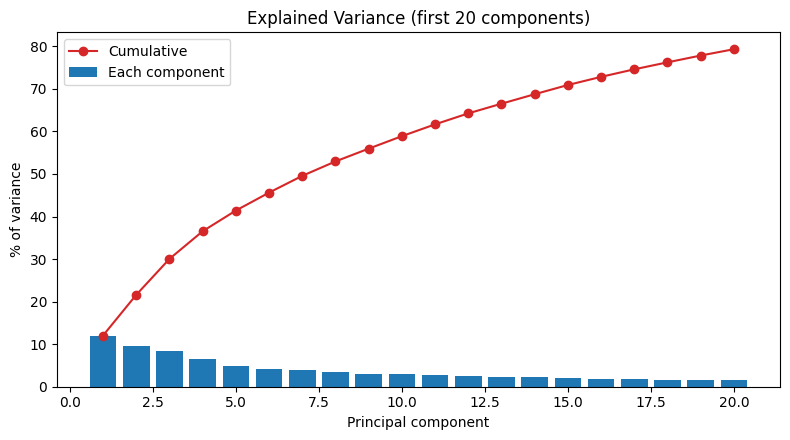

In [5]:
# Fit with ALL components to see every one of them
pca_full = PCA().fit(X_scaled)
ratios = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratios)

print("First 5 components:", (ratios[:5] * 100).round(1))
print("Cumulative first 5:", (cumulative[:5] * 100).round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, 21), ratios[:20] * 100, color="#1f77b4", label="Each component")
ax.plot(range(1, 21), cumulative[:20] * 100, color="#d62728", marker="o", label="Cumulative")
ax.set_xlabel("Principal component")
ax.set_ylabel("% of variance")
ax.set_title("Explained Variance (first 20 components)")
ax.legend()
plt.tight_layout()
plt.savefig("images/explained_variance_bar_cumulative.png", dpi=150)
plt.show()

## Example 3: How many components for 95%?

In [6]:
# By hand: first place where the running total reaches 95%
n_95 = int(np.argmax(cumulative >= 0.95)) + 1
print("Components for 95%:", n_95, "out of", X.shape[1])

# The shortcut: give PCA a fraction instead of a number
pca_95 = PCA(n_components=0.95).fit(X_scaled)
print("PCA(n_components=0.95) picked:", pca_95.n_components_)

Components for 95%: 40 out of 64
PCA(n_components=0.95) picked: 40


80 % of variance needs 21 components
90 % of variance needs 31 components
95 % of variance needs 40 components
99 % of variance needs 54 components


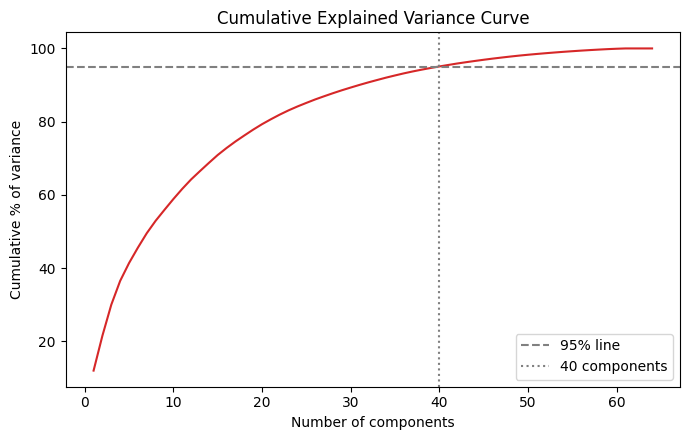

In [7]:
for target in [0.80, 0.90, 0.95, 0.99]:
    k = int(np.argmax(cumulative >= target)) + 1
    print(int(target * 100), "% of variance needs", k, "components")

plt.figure(figsize=(7, 4.5))
plt.plot(range(1, 65), cumulative * 100, color="#d62728")
plt.axhline(95, color="gray", linestyle="--", label="95% line")
plt.axvline(n_95, color="gray", linestyle=":", label=str(n_95) + " components")
plt.xlabel("Number of components")
plt.ylabel("Cumulative % of variance")
plt.title("Cumulative Explained Variance Curve")
plt.legend()
plt.tight_layout()
plt.savefig("images/cumulative_variance_curve.png", dpi=150)
plt.show()

## Example 4: Project 64 dimensions into 2D

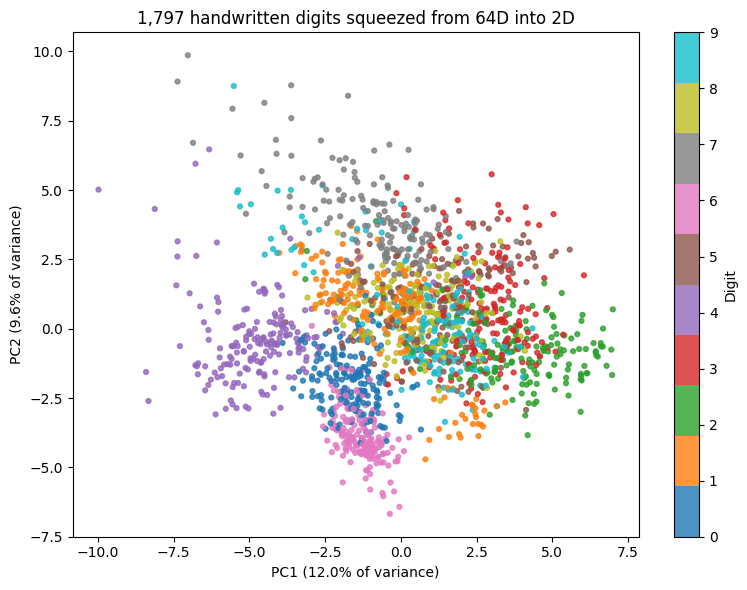

In [8]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="tab10", s=12, alpha=0.8)
plt.colorbar(scatter, label="Digit")
plt.xlabel("PC1 (" + str(round(pca2.explained_variance_ratio_[0] * 100, 1)) + "% of variance)")
plt.ylabel("PC2 (" + str(round(pca2.explained_variance_ratio_[1] * 100, 1)) + "% of variance)")
plt.title("1,797 handwritten digits squeezed from 64D into 2D")
plt.tight_layout()
plt.savefig("images/pca_digits_2d.png", dpi=150)
plt.show()

## Example 5: Does PCA hurt a model? (leak-free)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

def accuracy_with(n_components):
    # Scaler and PCA are fitted on the training data only
    steps = [StandardScaler()]
    if n_components is not None:
        steps.append(PCA(n_components=n_components))
    steps.append(LogisticRegression(max_iter=2000))
    model = make_pipeline(*steps).fit(X_train, y_train)
    return round(accuracy_score(y_test, model.predict(X_test)), 3)

print("All 64 features:   ", accuracy_with(None))
print("2 components:      ", accuracy_with(2))
print("95% of variance:   ", accuracy_with(0.95))

All 64 features:    0.978
2 components:       0.511
95% of variance:    0.96


## Example 6: What a component really is

In [10]:
# Each component is 64 weights, one per pixel
print("components_ shape:", pca_95.components_.shape)
print("Weights of PC1 (first 5 pixels):", pca_95.components_[0][:5].round(3))

components_ shape: (40, 64)
Weights of PC1 (first 5 pixels): [-0.     0.182  0.286  0.22  -0.025]


## Practice Exercise
How many components does PCA need to keep 99% of the variance? How much smaller is that than 64?

In [11]:
pca_99 = PCA(n_components=0.99).fit(X_scaled)
print("Components for 99%:", pca_99.n_components_)
print("Reduction:", round((1 - pca_99.n_components_ / 64) * 100, 1), "% fewer columns")

Components for 99%: 54
Reduction: 15.6 % fewer columns


## Mini Challenge
Find the smallest number of components (from a list) that gets within 0.02 accuracy of using all 64 features.

In [12]:
baseline = accuracy_with(None)
for n in [2, 5, 10, 20, 30, 40]:
    acc = accuracy_with(n)
    flag = "<-- within 0.02" if acc >= baseline - 0.02 else ""
    print(n, "components ->", acc, flag)

2 components -> 0.511 


5 components -> 0.784 
10 components -> 0.858 


20 components -> 0.942 
30 components -> 0.949 
40 components -> 0.96 <-- within 0.02


## Summary
- `PCA(n_components=k).fit_transform(X_scaled)` gives the new, smaller table
- `explained_variance_ratio_` shows each component's share, and the cumulative sum picks k
- `PCA(n_components=0.95)` chooses k for you
- 2D scatter plots reveal structure in high-dimensional data
- In a model, fit scaler and PCA on training data only (use a pipeline)